# Import Dependency

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import matplotlib.pyplot as plt
from pathlib import Path
from functools import partial
import numpy as np

import itertools

import autograd.numpy as anp
from autograd import value_and_grad as auto_value_and_grad
import nlopt
import matplotlib.pyplot as plt
from top_opt_framework import problems
from top_opt_framework import topo_api
from top_opt_framework import topo_physics
from scipy.ndimage import zoom
import math

# Beam Settings

In [2]:
# initial beam number
N = 20
beam_stock_prams = np.array([0, 10, 20,30,40], dtype=float)
beam_stock_numbs = np.array([30, 9, 8, 7, 6], dtype=int)

# beam_stock_prams = np.array([0, 10, 16, 22, 28, 34, 40], dtype=float)
# beam_stock_numbs = np.array([30, 7,7,3,3,2,2], dtype=int)


MAX_LENGTH = float(beam_stock_prams[-1])
BEAM_WIDTH = 1 # only for one-side, full width is BEAM_WIDTH*2

img_h = 300
img_w = 300
grid_w = 180
grid_h = 120
sharpness = 2
n_shapes = N

# Basis Function (Sec. 3.3)

In [3]:
# linear hat function B_i centered at l_cur, support (l_prev, l_next)
def hat_func(l, l_prev, l_cur, l_next, has_prev, has_next):
    if has_prev:
        left_val = (l - l_prev) / (l_cur - l_prev)
        left_val = anp.where((l > l_prev) & (l <= l_cur), left_val, 0.0)
    else:
        left_val = anp.where(l <= l_cur, 1.0, 0.0)

    if has_next:
        right_val = (l_next - l) / (l_next - l_cur)
        right_val = anp.where(l > l_cur, right_val, 0.0)
        right_val = anp.where(l > l_next, 0.0, right_val)
    else:
        right_val = 0.0

    return left_val + right_val


# midpoint hat function B'_{i,i+1}: supported on (l_i, l_{i+1}),
# zero at both stock lengths, peak = 1 at the midpoint
def midpoint_hat_func(l, l_i, l_ip1):
    mid = (l_i + l_ip1) / 2.0

    left_val = (l - l_i) / (mid - l_i)
    left_val = anp.where((l > l_i) & (l <= mid), left_val, 0.0)

    right_val = (l_ip1 - l) / (l_ip1 - mid)
    right_val = anp.where((l > mid) & (l < l_ip1), right_val, 0.0)

    return left_val + right_val


# L_stock: softplus barrier on stock inventory violation, Eq. (10)
def soft_stock_func(lens, beam_stock_prams, beam_stock_numbs, eta_s=5.0):
    M = len(beam_stock_prams)

    bucket_counts = []
    for j in range(M):
        has_prev = j > 0
        has_next = j < M - 1
        l_prev = beam_stock_prams[j - 1] if has_prev else 0.0
        l_cur = beam_stock_prams[j]
        l_next = beam_stock_prams[j + 1] if has_next else 0.0

        s = anp.sum(hat_func(lens, l_prev, l_cur, l_next, has_prev, has_next))
        bucket_counts.append(s)

    total_stock_nums = anp.stack(bucket_counts)
    cost = anp.sum(anp.log1p(anp.exp(eta_s * (total_stock_nums - beam_stock_numbs))))
    return cost


# L_rounding: drives beam lengths toward discrete stock lengths, Eq. (12)
def rounding_func(lens, beam_stock_prams):
    cost = 0.0
    for i in range(len(beam_stock_prams) - 1):
        b = midpoint_hat_func(lens, beam_stock_prams[i], beam_stock_prams[i + 1])
        cost = cost + anp.sum(b ** 2)
    return cost


# Beam Merging (Sec. 3.6)

In [4]:
def save_beam_txt(path, joint_xy_init, beam_joint_pairs):
    with open(path, "w") as f:
        f.write("# joints (x y)\n")
        f.write(f"{len(joint_xy_init)}\n")
        for x, y in joint_xy_init:
            f.write(f"{x:.6f} {y:.6f}\n")
        f.write("# beams (i0 i1)\n")
        f.write(f"{len(beam_joint_pairs)}\n")
        for i0, i1 in beam_joint_pairs:
            f.write(f"{i0} {i1}\n")


def load_beam_txt(path):
    with open(path) as f:
        lines = [ln.strip() for ln in f if ln.strip() and not ln.startswith("#")]
    m = int(lines[0])
    joint_xy_init = np.array([ln.split() for ln in lines[1:1 + m]], dtype=float)
    n = int(lines[1 + m])
    beam_joint_pairs = np.array([ln.split() for ln in lines[2 + m:2 + m + n]], dtype=int)
    return joint_xy_init, beam_joint_pairs


def params_to_joints(params_flat, tol=1e-6):
    N = len(params_flat) // 4
    x, y, theta, alpha = np.asarray(params_flat).reshape(4, N)

    half_h = alpha * MAX_LENGTH / 2.0

    dx = -np.sin(theta) * half_h
    dy =  np.cos(theta) * half_h
    p0 = np.stack([x - dx, y - dy], axis=1)          # (N, 2)
    p1 = np.stack([x + dx, y + dy], axis=1)          # (N, 2)
    endpoints = np.concatenate([p0, p1], axis=0)     # (2N, 2)

    joints = []
    idx_of = np.empty(2 * N, dtype=int)
    for k, p in enumerate(endpoints):
        for j, q in enumerate(joints):
            if np.hypot(*(p - q)) < tol:
                idx_of[k] = j
                break
        else:
            idx_of[k] = len(joints)
            joints.append(p)

    joint_xy_init = np.array(joints, dtype=float)                        # (M, 2)
    beam_joint_pairs = np.stack([idx_of[:N], idx_of[N:]], axis=1)        # (N, 2)
    return joint_xy_init, beam_joint_pairs


def beam_length(alpha):
    return alpha * MAX_LENGTH


def length_to_alpha(L, eps=1e-12):
    L_clip = float(np.clip(L, 0.0, MAX_LENGTH))
    clipped = abs(L_clip - L) > 1e-9
    a = 0.0 if MAX_LENGTH <= eps else L_clip / MAX_LENGTH
    return float(np.clip(a, 0.0, 1.0)), clipped


def _long_axis(theta):
    return np.array([-np.sin(theta), np.cos(theta)])


def _get_beam(params, n, i):
    return (params[0*n+i], params[1*n+i],
            params[2*n+i], params[3*n+i])   # cx, cy, theta, alpha


def _endpoints(cx, cy, theta, hl):
    d = _long_axis(theta)
    c = np.array([cx, cy])
    return c + hl*d, c - hl*d, d


def _write_interval(params_out, n, i, p_lo, p_hi, origin, d, theta, log, tag):
    L = p_hi - p_lo
    a, clipped = length_to_alpha(L)
    if clipped:
        log.append(f"[warn] beam {i} target len={L:.2f} clipped to "
                   f"[0.0,{MAX_LENGTH:.1f}] ({tag})")
        L = beam_length(a)
    p_mid = (p_lo + p_hi) / 2.0
    params_out[0*n+i] = origin[0] + p_mid * d[0]
    params_out[1*n+i] = origin[1] + p_mid * d[1]
    params_out[2*n+i] = theta
    params_out[3*n+i] = a


def _soft_delete(params_out, n, j):
    params_out[3*n+j] = 0.0


def _are_parallel(ti, tj, angle_tol):
    diff = (ti - tj) % np.pi
    return diff < angle_tol or diff > np.pi - angle_tol


def _lateral_dist(P, origin, d):
    proj = float(np.dot(P - origin, d))
    foot = origin + proj * d
    return float(np.linalg.norm(P - foot))


def _proj(P, origin, d):
    return float(np.dot(P - origin, d))


def postprocess_beams(params,
                      angle_tol=np.deg2rad(5),
                      lateral_tol=2.0,
                      merge_gap=3.0,
                      eps=1e-9):
    """
    params      : (4*N,) ndarray  [x | y | theta | alpha]
    angle_tol   : angular tolerance for parallelism (radians)
    lateral_tol : lateral (perpendicular) distance tolerance for collinearity
    merge_gap   : endpoints within this gap are also eligible for merging
    """
    L_MAX = MAX_LENGTH

    params_out = np.asarray(params, dtype=float).copy()
    n = len(params_out) // 4
    keep = np.ones(n, dtype=bool)
    log = []

    for i in range(n):
        for j in range(i+1, n):
            if not keep[i]:
                break
            if not keep[j]:
                continue

            # Re-read each round to use the latest geometry
            cx_i, cy_i, th_i, al_i = _get_beam(params_out, n, i)
            len_i = beam_length(al_i)
            A_i, B_i, d_i = _endpoints(cx_i, cy_i, th_i, len_i / 2.0)
            origin_i = np.array([cx_i, cy_i])

            cx_j, cy_j, th_j, al_j = _get_beam(params_out, n, j)
            len_j = beam_length(al_j)

            # ── 1. Parallel ─────────────────────────────────────────────
            if not _are_parallel(th_i, th_j, angle_tol):
                continue

            # ── 2. Laterally collinear ──────────────────────────────────
            if _lateral_dist(np.array([cx_j, cy_j]), origin_i, d_i) > lateral_tol:
                continue

            # ── 3. Project onto beam i's long axis, normalize so p_C >= p_D ──
            A_j, B_j, _ = _endpoints(cx_j, cy_j, th_j, len_j / 2.0)
            p_A, p_B = len_i / 2.0, -len_i / 2.0
            p_C = _proj(A_j, origin_i, d_i)
            p_D = _proj(B_j, origin_i, d_i)
            if p_C < p_D:
                p_C, p_D = p_D, p_C

            overlap = min(p_A, p_C) - max(p_B, p_D)
            gap     = -overlap
            if overlap <= 0 and gap > merge_gap:
                continue

            union_lo  = min(p_B, p_D)
            union_hi  = max(p_A, p_C)
            union_len = union_hi - union_lo

            # ── Merge: the union fits within one stock length ────────────
            if union_len <= L_MAX + eps:
                _write_interval(params_out, n, i, union_lo, union_hi,
                                origin_i, d_i, th_i, log, tag=f"merge {i}&{j}")
                keep[j] = False
                _soft_delete(params_out, n, j)
                log.append(f"[M] beams {i}&{j} merged: "
                           f"[{union_lo:.1f},{union_hi:.1f}] len={union_len:.1f} "
                           f"→ beam {i} (alpha={params_out[3*n+i]:.3f}), "
                           f"beam {j} soft-deleted (alpha=0)")
                continue

            # ── Small gap but union too long → keep as is ────────────────
            if overlap <= 0:
                log.append(f"[skip] beams {i}&{j} adjacent (gap={gap:.1f}) "
                           f"but union len={union_len:.1f} > L_max={L_MAX:.1f}")
                continue

            # ── Split: interleaved and union too long → cut at the overlap midpoint, end-to-end ──
            snap = (max(p_B, p_D) + min(p_A, p_C)) / 2.0
            if p_A >= p_C:      # i reaches farther on the right → i takes the right segment
                iv_i, iv_j = (snap, union_hi), (union_lo, snap)
            else:
                iv_i, iv_j = (union_lo, snap), (snap, union_hi)
            _write_interval(params_out, n, i, *iv_i,
                            origin_i, d_i, th_i, log, tag=f"split {i}")
            _write_interval(params_out, n, j, *iv_j,
                            origin_i, d_i, th_i, log, tag=f"split {j}")
            log.append(f"[S] beams {i}&{j} split at snap={snap:.2f}: "
                       f"beam {i} [{iv_i[0]:.1f},{iv_i[1]:.1f}]  "
                       f"beam {j} [{iv_j[0]:.1f},{iv_j[1]:.1f}]")

    return params_out, keep, log


def postprocess_and_report(params,
                           angle_tol=np.deg2rad(5),
                           lateral_tol=2.0,
                           merge_gap=3.0):
    """
    Usage:
        params_post, keep, log = postprocess_and_report(frames[-1])
        # Array length is unchanged; beams with keep[j]=False are marked alpha=0.
        # Filter downstream with keep as needed:
        joint_xy_init, beam_joint_pairs = params_to_joints(params_post)
    """
    params_post, keep, log = postprocess_beams(
        params, angle_tol=angle_tol, lateral_tol=lateral_tol, merge_gap=merge_gap)
    n_M = sum(1 for l in log if l.startswith('[M]'))
    n_S = sum(1 for l in log if l.startswith('[S]'))
    print(f"Post-processing done: {len(keep)} beams, {int(keep.sum())} alive "
          f"({int((~keep).sum())} soft-deleted, alpha=0)")
    print(f"  merges: {n_M}   splits (de-overlap): {n_S}")
    for entry in log:
        print(" ", entry)
    return params_post, keep, log

# Beam Parameters Initialization (Sec. 3.4)

In [5]:
import numpy as np
import autograd.numpy as anp



def alphas2lengths(alphas, beam_stock_prams):
    """alpha in [0,1] -> continuous length in [0, MAX_LENGTH]."""
    h1 = beam_stock_prams[0]
    h2 = beam_stock_prams[-1]
    return (1 - alphas) * h1 + alphas * h2

def random_continuous_params(N, x_range, y_range):
    """Returns flat (4N,) array: [x | y | theta | alpha]."""
    x     = np.random.uniform(x_range[0], x_range[1], N)
    y     = np.random.uniform(y_range[0], y_range[1], N)
    theta = np.random.uniform(0, np.pi, N)
    alpha = np.random.uniform(0.5, 1, N)
    return np.concatenate([x, y, theta, alpha])

def initialize_params(N, x_range, y_range):
    x = np.linspace(x_range[0] + 5, x_range[1] - 5, N)
    y = np.random.uniform(y_range[0]+5, y_range[1]-5, N)
    theta = np.ones(N) * 0
    alpha = np.random.uniform(0.25, 1, N)
    return np.concatenate([x, y, theta, alpha])


def _beam_grids_soft(params, grid_w, grid_h, x_range, y_range, sharpness):
    N = params.shape[0]
    cx, cy, th, al = params[:, 0], params[:, 1], params[:, 2], params[:, 3]
    half_h = al * MAX_LENGTH / 2.0                             # (N,)
    half_w = BEAM_WIDTH / 2.0

    xs = np.linspace(x_range[0], x_range[1], grid_w)
    ys = np.linspace(y_range[0], y_range[1], grid_h)
    XX, YY = np.meshgrid(xs, ys)                                # (H,W)

    dx = XX[None, :, :] - cx[:, None, None]                     # (N,H,W)
    dy = YY[None, :, :] - cy[:, None, None]
    c = anp.cos(th)[:, None, None]
    s = anp.sin(th)[:, None, None]
    lx =  c * dx + s * dy
    ly = -s * dx + c * dy

    sx = 1.0 / (1.0 + anp.exp(-sharpness * (half_w                 - anp.abs(lx))))
    sy = 1.0 / (1.0 + anp.exp(-sharpness * (half_h[:, None, None]  - anp.abs(ly))))

    gate_y = 1.0 - anp.exp(-2.0 * sharpness * half_h[:, None, None])
    return sx * sy * gate_y                                     # (N,H,W)

def params_to_density_map(params_batch, grid_w, grid_h,
                          x_range, y_range, sdf_x_range=None, sdf_y_range=None,
                          sharpness=2.0):
    N = params_batch.shape[0] // 4
    params = params_batch.reshape(4, N).T

    soft = _beam_grids_soft(params, grid_w, grid_h, x_range, y_range, sharpness)
    union = 1.0 - anp.prod(1.0 - soft, axis=0)
    density = union * (1.0 - 0.001) + 0.001
    return density

def params_to_overlap_map(params_batch, grid_w, grid_h,
                          x_range, y_range, sdf_x_range=None, sdf_y_range=None,
                          sharpness=2.0):
    N = params_batch.shape[0] // 4
    params = params_batch.reshape(4, N).T
    soft = _beam_grids_soft(params, grid_w, grid_h, x_range, y_range, sharpness)
    return anp.sum(soft, axis=0)

In [6]:
sdf_x_range = (-25, 25)
sdf_y_range = (-25, 25)
x_range = (-60, 60)
y_range = (-40, 40)

params_batch = initialize_params(n_shapes, x_range, y_range)

density_map = params_to_density_map(
    params_batch,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)
overlap_map = params_to_overlap_map(
    params_batch,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)


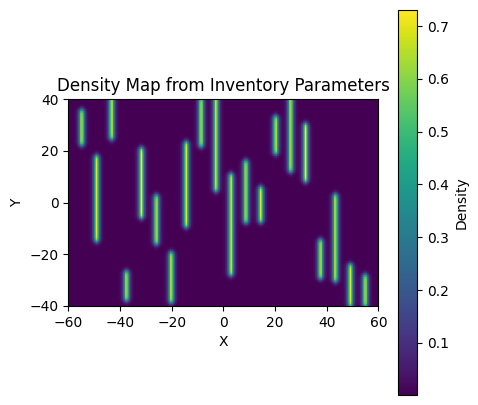

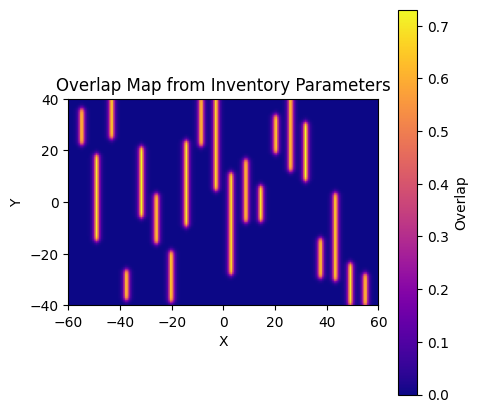

In [7]:
# visualize the density map
plt.figure(figsize=(5, 5))
plt.imshow(density_map, extent=(x_range[0], x_range[1], y_range[0], y_range[1]), origin='lower', cmap='viridis')
plt.title('Density Map from Inventory Parameters')
plt.xlabel('X')
plt.ylabel('Y')
plt.colorbar(label='Density')
plt.show()

# visualize the overlap map
plt.figure(figsize=(5, 5))
plt.imshow(overlap_map, extent=(x_range[0], x_range[1], y_range[0], y_range[1]), origin='lower', cmap='plasma')
plt.title('Overlap Map from Inventory Parameters')
plt.xlabel('X')
plt.ylabel('Y')
plt.colorbar(label='Overlap')
plt.show()

In [8]:
params_batch

array([-55.        , -49.21052632, -43.42105263, -37.63157895,
       -31.84210526, -26.05263158, -20.26315789, -14.47368421,
        -8.68421053,  -2.89473684,   2.89473684,   8.68421053,
        14.47368421,  20.26315789,  26.05263158,  31.84210526,
        37.63157895,  43.42105263,  49.21052632,  55.        ,
        29.20541967,   1.52366308,  34.35732433, -32.49613576,
         7.58403044,  -6.71351112, -29.24378712,   7.0039385 ,
        31.24364162,  23.71849638,  -8.61859373,   4.20686312,
        -0.82350011,  26.25081412,  28.82156987,  19.40704773,
       -22.08472419, -13.80259452, -32.247154  , -34.38082362,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.        ,   0.        ,   0.        ,   0.        ,
         0.3494857 ,   0.84033668,   0.49178686,   0.29

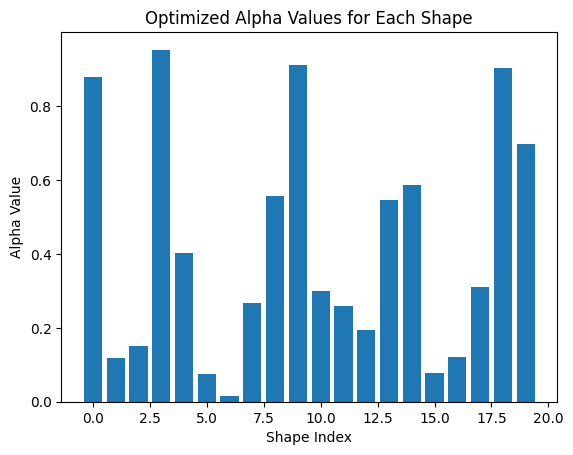

In [9]:
# show alphas
N = len(params_batch) // 4
params_batch[3*N:4*N] = np.random.uniform(0, 1, N)
alphas = params_batch.reshape(4, N)[3]
plt.bar(range(N), alphas)
plt.xlabel("Shape Index")
plt.ylabel("Alpha Value")
plt.title("Optimized Alpha Values for Each Shape")
plt.show()


# Boundary Condition Settings

### You can change the boundary condition here

121 fixed nodes


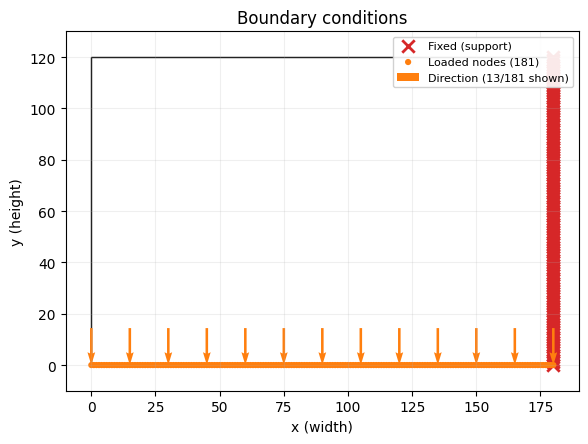

In [10]:
import numpy as np
import matplotlib.pyplot as plt

def plot_boundary_conditions(problem, ax=None, density=None,
                             pad=None, load_stride=None, fix_stride=1):
    normals = np.asarray(problem.normals)
    forces  = np.asarray(problem.forces)
    Wp1, Hp1, _ = normals.shape
    W, H = Wp1 - 1, Hp1 - 1

    if pad is None:
        pad = 0.10 * max(W, H)

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 7 * H / max(W, 1)))

    if density is not None:
        ax.imshow(np.asarray(density).T, origin='lower', cmap='gray_r',
                  extent=(0, W, 0, H), vmin=0, vmax=1, alpha=0.6)
    else:
        ax.add_patch(plt.Rectangle((0, 0), W, H, fill=False, ec='black', lw=1))

    ii, jj = np.meshgrid(np.arange(Wp1), np.arange(Hp1), indexing='ij')

    fixed_any = (normals[..., 0] > 0) | (normals[..., 1] > 0)
    fix_i, fix_j = ii[fixed_any], jj[fixed_any]
    if fix_stride > 1 and len(fix_i):
        fix_i = fix_i[::fix_stride]; fix_j = fix_j[::fix_stride]
    print(len(fix_i), "fixed nodes")
    ax.scatter(fix_i, fix_j, marker='x', s=80, c='tab:red', linewidths=2,
               label='Fixed (support)')

    fxv = forces[..., 0]; fyv = forces[..., 1]
    has_load = (fxv != 0) | (fyv != 0)
    li_all, lj_all = ii[has_load], jj[has_load]

    if len(li_all):
        ax.scatter(li_all, lj_all, marker='o', s=20,
                   c='tab:orange', edgecolors='none',
                   label=f'Loaded nodes ({len(li_all)})')

    lux_all = fxv[has_load]; luy_all = fyv[has_load]
    n_loads = len(li_all)
    if n_loads:
        if load_stride is None:
            load_stride = max(1, n_loads // 12)
        sel = slice(None, None, load_stride)
        li, lj = li_all[sel], lj_all[sel]
        lux, luy = lux_all[sel], luy_all[sel]
        mag = np.sqrt(lux**2 + luy**2) + 1e-12
        ux, uy = lux / mag, luy / mag
        arrow_len = 0.08 * max(W, H)
        x0 = li - ux * arrow_len
        y0 = lj - uy * arrow_len
        ax.quiver(x0, y0, ux * arrow_len, uy * arrow_len,
                  angles='xy', scale_units='xy', scale=1.0,
                  color='tab:orange', width=0.005,
                  label=f'Direction ({len(li)}/{n_loads} shown)')

    ax.set_xlim(-pad, W + pad)
    ax.set_ylim(-pad, H + pad)
    ax.set_aspect('equal')
    ax.set_xlabel('x (width)'); ax.set_ylabel('y (height)')
    ax.set_title('Boundary conditions')
    ax.legend(loc='upper right', fontsize=8, framealpha=0.9)
    ax.grid(alpha=0.2)
    return ax


###########################################
#
# You can change boundary conditions here
#
# In our paper, we used following examples
# center_support
# mbb
# example2
# example
# cube
# staircase
# compare_case1 (2/4/5/6)
###########################################
problem = problems.center_support(height=grid_h, width=grid_w)




args = topo_api.specified_task(problem)
args["youngs_modulus"] = 1.0
args["volfrac"]=0.1
args["filter_width"]=1
env = topo_api.Environment(args)

nely = grid_h
nelx = grid_w

density_func = lambda x : params_to_density_map(
    x,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)
overlap_func = lambda x: params_to_overlap_map(
    x,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)
compliance_fn = lambda x: env.objective(density_func(x), volume_constraint=False)

# Usage:plot_boundary_conditions(problem, pad=5, load_stride=8)   # very sparse
plot_boundary_conditions(problem, pad=10)                  # auto stride
plt.show()

# Density Method (SIMP)

In [11]:
density_frames = []
oc_iterations = 50

args["filter_width"]=2
env = topo_api.Environment(args)
oc_x = np.ones((grid_h, grid_w)) * 0.1
for it in range(oc_iterations):
    c, x_next = topo_physics.optimality_criteria_step(oc_x, env.ke, env.args)
    # x_next[62:120, :] = 0.001
    # x_next[50:, 50:] = 0.001
    density_frames.append(x_next)
    if np.isnan(c):
        print(f"NaN encountered at iteration {it}, stopping.")
        break
    oc_x = x_next

args["filter_width"]=1
env = topo_api.Environment(args)

In [12]:
# oc_x[:,:] = 0.01
# oc_x[50:, 50:] = 1.01

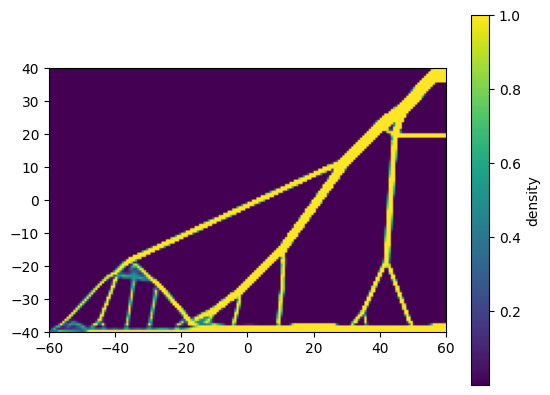

In [13]:
from scipy.ndimage import uniform_filter
from skimage.restoration import inpaint_biharmonic 
# oc_x = uniform_filter(oc_x, size=1)

# mask_unknown = oc_x <= 0.4
# u = inpaint_biharmonic(oc_x, mask_unknown)
# oc_x[oc_x < 0.2] = 0
plt.imshow(oc_x, extent=(*x_range, *y_range), origin='lower')
plt.colorbar(label='density')
plt.show()

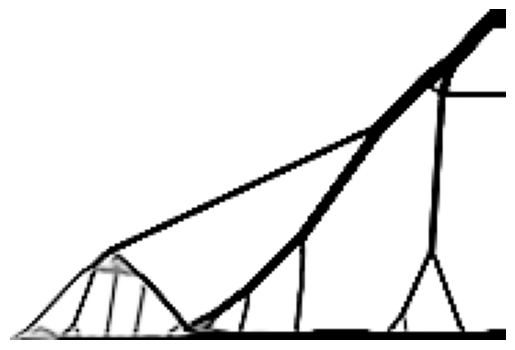

In [14]:
plt.imshow(oc_x, extent=(*x_range, *y_range), origin='lower',
           cmap='gray_r', vmin=0, vmax=1)
# plt.colorbar(label='density')
plt.axis('off')
plt.gcf().patch.set_facecolor('white')
plt.show()

In [15]:
env.objective(oc_x)

63.70501783282822

In [16]:
np.mean(oc_x)

0.10013225452265755

# Visualize the Gradient Flow

compliance = 4178896002.936243
sens shape  = (120, 180)  min/max = -1674782892629.7085 28487.95370112746


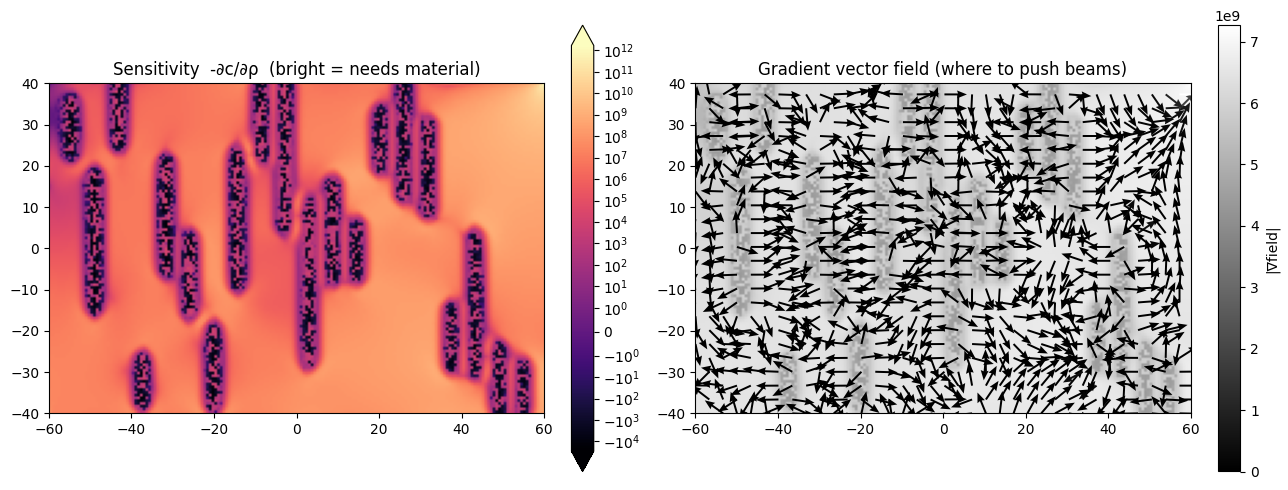

In [17]:
import autograd.numpy as anp
from autograd import value_and_grad as auto_value_and_grad
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from matplotlib.colors import SymLogNorm

density0 = density_map

def sensitivity_loss(density):                       
    compliance_grad = auto_value_and_grad(env.objective)(density)[1]
    sensitivity_norm = (compliance_grad - compliance_grad.min()) / (compliance_grad.max() - compliance_grad.min() + 1e-8)
    dark_weight = 1.0 - sensitivity_norm             
    return anp.sum(density * dark_weight)

def overlap_loss(x):
    return anp.sum(anp.log1p(anp.exp(5 * (x - 1))))

compliance, sens = auto_value_and_grad(
    lambda d:
      env.objective(d, volume_constraint=False)
)(density0)

print("compliance =", float(compliance))
print("sens shape  =", sens.shape, " min/max =", sens.min(), sens.max())

field = -sens

field = np.asarray(field, dtype=float)

gy, gx = np.gradient(field)

step = max(1, min(grid_h, grid_w) // 22)
ys, xs = np.mgrid[0:grid_h:step, 0:grid_w:step]
U = gx[::step, ::step]
V = gy[::step, ::step]

mag = np.hypot(U, V)
Un = U / (mag + 1e-8)
Vn = V / (mag + 1e-8)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

im = ax[0].imshow(
    field, origin='lower', extent=(*x_range, *y_range), cmap='magma',
    norm=SymLogNorm(linthresh=1, vmin=field.min(), vmax=field.max())
)
ax[0].set_title("Sensitivity  -∂c/∂ρ  (bright = needs material)")
plt.colorbar(im, ax=ax[0], fraction=0.046, extend='both')

ax[1].imshow(field, origin='lower', extent=(*x_range, *y_range),
             cmap='gray', alpha=0.4,
             norm=SymLogNorm(linthresh=1, vmin=field.min(), vmax=field.max()))
xw = anp.interp(xs, [0, grid_w - 1], x_range)
yw = anp.interp(ys, [0, grid_h - 1], y_range)

q = ax[1].quiver(xw, yw, Un, Vn, mag,
                 cmap='gray', angles='xy',
                 scale_units='width', scale=22,  
                 width=0.004,                    
                 headwidth=4, headlength=5, headaxislength=4.5)
plt.colorbar(q, ax=ax[1], fraction=0.046, label='|∇field|')
ax[1].set_title("Gradient vector field (where to push beams)")
ax[1].set_xlim(x_range); ax[1].set_ylim(y_range)
plt.tight_layout(); plt.show()

# Objective Function Settings (Sec. 3.3)

In [18]:
weight_compliance = 5
weight_overlap = 10
weight_length = 100
weight_stock = 1000
weight_rounding = 10

In [19]:
def boundary_loss(params_batch, x_range, y_range):
    N = params_batch.shape[0] // 4
    params = params_batch.reshape(4, N).T  # (N, 4)

    xs     = params[:, 0]
    ys     = params[:, 1]
    thetas = params[:, 2]
    alphas = params[:, 3]

    # Beam half-extents in local frame: 长度 = alpha * MAX_LENGTH
    heights = alphas * MAX_LENGTH               # (N,) anp
    hw = BEAM_WIDTH / 2.0
    hh = heights / 2.0                          # (N,) anp

    # 4 corners in local frame, shape (N, 4, 2)
    # Order: (-hw,-hh), (+hw,-hh), (+hw,+hh), (-hw,+hh)
    sign_x = np.array([-1.0, 1.0, 1.0, -1.0])   # (4,)
    sign_y = np.array([-1.0, -1.0, 1.0, 1.0])   # (4,)
    local_x = sign_x[np.newaxis, :] * hw                    # (1, 4)
    local_y = sign_y[np.newaxis, :] * hh[:, np.newaxis]     # (N, 4)

    # Rotate + translate to world frame
    c = anp.cos(thetas)[:, np.newaxis]  # (N, 1)
    s = anp.sin(thetas)[:, np.newaxis]
    world_x = c * local_x - s * local_y + xs[:, np.newaxis]  # (N, 4)
    world_y = s * local_x + c * local_y + ys[:, np.newaxis]

    # Penalize amount outside the box (squared hinge)
    x_min, x_max = x_range
    y_min, y_max = y_range
    over = (anp.maximum(0.0, x_min - world_x) ** 2
          + anp.maximum(0.0, world_x - x_max) ** 2
          + anp.maximum(0.0, y_min - world_y) ** 2
          + anp.maximum(0.0, world_y - y_max) ** 2)

    return anp.sum(over)

def overlap_loss(x):
    return anp.sum(anp.log1p(anp.exp(5 * (x - 0.75))))
    # return anp.sum(anp.exp(5 * (x - 0.75)))

boundary_fn = lambda x: boundary_loss(x, x_range, y_range)
overlap_fn = lambda x: (overlap_loss(overlap_func(x)))
constraint_fn = lambda x: (density_func(x)*oc_x).sum()

def gradloss_fn(x):
    density_field = density_func(x)
    compliance_grad = auto_value_and_grad(env.objective)(density_field)[1]
    _LOG10 = anp.log(10.0)
    compliance_grad_log = anp.sign(compliance_grad) * anp.log(anp.abs(compliance_grad) + 1e-5) / _LOG10
    min_grad_log = anp.min(compliance_grad_log)
    compliance_grad_log = compliance_grad_log - min_grad_log
    return anp.sum(compliance_grad_log*density_field)

match_target_fn = lambda x: anp.sum(anp.abs(density_func(x) - oc_x))

def compliance_sens_loss(x):
    density_field = density_func(x)
    compliance_grad = auto_value_and_grad(env.objective)(density_field)[1]
    compliance_grad = anp.log10(- compliance_grad + 1e-5)
    return anp.sum(compliance_grad * density_field)

def sensitivity_weighted_coverage_loss(x):
    density = density_func(x)
    compliance_grad = auto_value_and_grad(env.objective)(density)[1]
    sensitivity_norm = (compliance_grad - compliance_grad.min()) / (compliance_grad.max() - compliance_grad.min() + 1e-8)
    dark_weight = 1.0 - sensitivity_norm
    return anp.sum(density * dark_weight)

def alpha_sum_loss(x):
    alphas = x.reshape(4, -1)[3]
    return anp.sum(alphas)

def volume_loss(x):
    density = density_func(x)
    return (((anp.mean(density) - 0.066)*100)**2)**5

def avoid_region_loss(x, avoid_mask):
    density_field = density_func(x)
    overlap_with_mask = density_field * avoid_mask
    return anp.sum(overlap_with_mask)

avoid_fn = lambda x: avoid_region_loss(x, avoid_mask=oc_x)

objective_fn = lambda x: (
    compliance_fn(x)*weight_compliance
    + overlap_fn(x)*weight_overlap
    + alpha_sum_loss(x)*weight_length
    + soft_stock_func(alphas2lengths(x.reshape(4, -1)[3], beam_stock_prams), beam_stock_prams, beam_stock_numbs)*weight_stock
    + rounding_func(alphas2lengths(x.reshape(4, -1)[3], beam_stock_prams), beam_stock_prams)*weight_rounding
    # + avoid_fn(x)*10000
)


In [20]:
loss, g = auto_value_and_grad(objective_fn)(params_batch)

## Optimization Scheme (Sec. 3.5)

In [21]:
def topology_optmization(x, optimizer, iterations, ls_max_backtracks, ls_shrink, ls_tol, alpha_frozen_threshold):
    N = x.shape[0] // 4

    lower = torch.tensor([-60.]*N + [-40.]*N + [-float(np.inf)]*N + [0.]*N, dtype=torch.float64)
    upper = torch.tensor([ 60.]*N + [ 40.]*N + [float(np.inf)]*N + [1.]*N, dtype=torch.float64)

    # Index of the alpha block in the flat (4*N,) layout.
    alpha_idx_start = 3 * N
    # Per-beam frozen flag (True = its alpha has been rounded to 0 and locked).
    alpha_frozen = np.zeros(N, dtype=bool)

    losses, frames, loss_compliances = [], [], []

    x0_np = x.detach().cpu().numpy().copy()
    frames.append(x0_np)
    losses.append(float(objective_fn(x0_np)))
    x0_mask = density_func(x0_np).copy()
    x0_mask[x0_mask>0.4] = 1
    loss_compliances.append(env.objective(x0_mask))

    pbar = tqdm(total=iterations, desc="Optimizing", unit="step")
    for t in range(iterations):
        # Build a gradient mask matching x's layout: 0 on frozen-alpha slots, 1 elsewhere.
        grad_mask_np = np.ones(4 * N, dtype=np.float64)
        grad_mask_np[alpha_idx_start:][alpha_frozen] = 0.0
        grad_mask = torch.tensor(grad_mask_np, dtype=torch.float64)

        x_np = x.detach().cpu().numpy()
        loss, g = auto_value_and_grad(objective_fn)(x_np)
        loss_prev = float(loss)

        x_prev = x.detach().clone()

        # Adam: kill the gradient on frozen-alpha positions BEFORE the step.
        optimizer.zero_grad()
        g_t = torch.tensor(np.asarray(g, dtype=float), dtype=torch.float64) * grad_mask
        x.grad = g_t
        optimizer.step()
        with torch.no_grad():
            if alpha_frozen.any():
                xd = x.detach().cpu().numpy()
                xd[alpha_idx_start:][alpha_frozen] = 0.0
                x.copy_(torch.tensor(xd, dtype=torch.float64))
            x.clamp_(lower, upper)

        # ---- Backtracking line search ----
        scale = 1.0
        accepted_loss = loss_prev
        for _ in range(ls_max_backtracks):
            with torch.no_grad():
                new_loss = float(objective_fn(x.detach().cpu().numpy()))
            if np.isfinite(new_loss) and new_loss <= loss_prev * (1.0 + ls_tol):
                accepted_loss = new_loss
                break
            scale *= ls_shrink
            with torch.no_grad():
                x_interp = x_prev + scale * (x - x_prev) / (scale / ls_shrink)
                # Re-enforce frozen alphas on the interpolated point too.
                if alpha_frozen.any():
                    xi = x_interp.detach().cpu().numpy()
                    xi[alpha_idx_start:][alpha_frozen] = 0.0
                    x_interp = torch.tensor(xi, dtype=torch.float64)
                x.copy_(x_interp.clamp_(lower, upper))
        else:
            with torch.no_grad():
                x.copy_(x_prev)
            accepted_loss = loss_prev

        # ---- After the step is accepted: round any alpha < threshold to 0 and freeze ----
        with torch.no_grad():
            xd = x.detach().cpu().numpy()
            alpha_now = xd[alpha_idx_start:alpha_idx_start + N]
            newly = (alpha_now < alpha_frozen_threshold) & (~alpha_frozen)
            if newly.any():
                xd[alpha_idx_start:alpha_idx_start + N][newly] = 0.0
                x.copy_(torch.tensor(xd, dtype=torch.float64))
                alpha_frozen |= newly

                state = optimizer.state.get(x, None)
                if state is not None and 'exp_avg' in state:
                    idxs = np.where(newly)[0] + alpha_idx_start
                    idx_t = torch.tensor(idxs, dtype=torch.long)
                    state['exp_avg'].view(-1)[idx_t]    = 0.0
                    state['exp_avg_sq'].view(-1)[idx_t] = 0.0

        losses.append(accepted_loss)
        frames.append(x.detach().cpu().numpy().copy())
        pbar.update(1)

        mask_density = density_func(x.detach().cpu().numpy()).copy()
        mask_density[mask_density>0.4] = 1
        loss_compliance = env.objective(mask_density)
        loss_compliances.append(loss_compliance)
        pbar.set_postfix(
            loss=f"{accepted_loss:.4f}",
            compliance=f"{loss_compliance:.4f}",
            scale=f"{scale:.2f}",
            dead=f"{int(alpha_frozen.sum())}/{N}",
        )
    pbar.close()
    return x.detach().cpu().numpy(), losses, frames, loss_compliances


In [22]:
import torch, numpy as np
from tqdm.notebook import tqdm

iterations = 200
ls_max_backtracks = 16
ls_shrink = 0.5
ls_tol = 1e-3
alpha_frozen_threshold = 0.1
sharpness = 2
weight_rounding = 10

x = torch.tensor(np.array(params_batch), dtype=torch.float64, requires_grad=True)

all_frames, all_losses, all_compliances = [], [], []

# In this notebook, in order to show the full pipeline, we stop till the maximum intseration(here is 1000)
for cur_lr in [1, 0.5, 0.1, -1, 0.1, -1, 0.1]:
    if cur_lr == -1:
        params_post, keep, log = postprocess_and_report(
            frames[-1],
            angle_tol=np.deg2rad(5),
            lateral_tol=5.0,
            merge_gap=3.0,
        )
        x      = torch.tensor(np.array(params_post), dtype=torch.float64, requires_grad=True)
        frames = [params_post.copy()]
        weight_rounding = weight_rounding*30
        # all_frames.append(params_post.copy())
        # all_losses.append(float(objective_fn(params_post)))
        continue

    optimizer = torch.optim.Adam([x], lr=cur_lr)
    x, losses, frames, compliances = topology_optmization(x, optimizer, iterations, ls_max_backtracks, ls_shrink, ls_tol, alpha_frozen_threshold)
    all_frames.extend(frames)
    all_losses.extend(losses)
    all_compliances.extend(compliances)
    x = torch.tensor(np.array(x), dtype=torch.float64, requires_grad=True)

x_opt = x.detach().cpu().numpy()

Optimizing:   0%|          | 0/200 [00:00<?, ?step/s]

Optimizing:   0%|          | 0/200 [00:00<?, ?step/s]

Optimizing:   0%|          | 0/200 [00:00<?, ?step/s]

Post-processing done: 20 beams, 18 alive (2 soft-deleted, alpha=0)
  merges: 2   splits (de-overlap): 3
  [S] beams 3&6 split at snap=-6.32: beam 3 [-6.3,15.1]  beam 6 [-37.5,-6.3]
  [skip] beams 4&5 adjacent (gap=0.4) but union len=49.6 > L_max=40.0
  [M] beams 9&13 merged: [-13.3,20.8] len=34.0 → beam 9 (alpha=0.850), beam 13 soft-deleted (alpha=0)
  [S] beams 14&15 split at snap=13.50: beam 14 [-13.8,13.5]  beam 15 [13.5,33.0]
  [S] beams 16&18 split at snap=11.83: beam 16 [-20.0,11.8]  beam 18 [11.8,43.3]
  [M] beams 18&19 merged: [-15.7,15.9] len=31.7 → beam 18 (alpha=0.791), beam 19 soft-deleted (alpha=0)


Optimizing:   0%|          | 0/200 [00:00<?, ?step/s]

Post-processing done: 20 beams, 18 alive (2 soft-deleted, alpha=0)
  merges: 2   splits (de-overlap): 2
  [S] beams 4&5 split at snap=-10.60: beam 4 [-10.6,14.7]  beam 5 [-44.5,-10.6]
  [skip] beams 6&16 adjacent (gap=0.6) but union len=71.3 > L_max=40.0
  [M] beams 9&13 merged: [-15.0,15.0] len=30.0 → beam 9 (alpha=0.751), beam 13 soft-deleted (alpha=0)
  [S] beams 14&15 split at snap=14.76: beam 14 [-14.9,14.8]  beam 15 [14.8,34.7]
  [skip] beams 16&18 adjacent (gap=0.3) but union len=62.4 > L_max=40.0
  [M] beams 18&19 merged: [-15.6,15.6] len=31.1 → beam 18 (alpha=0.778), beam 19 soft-deleted (alpha=0)


Optimizing:   0%|          | 0/200 [00:00<?, ?step/s]

# Final Results

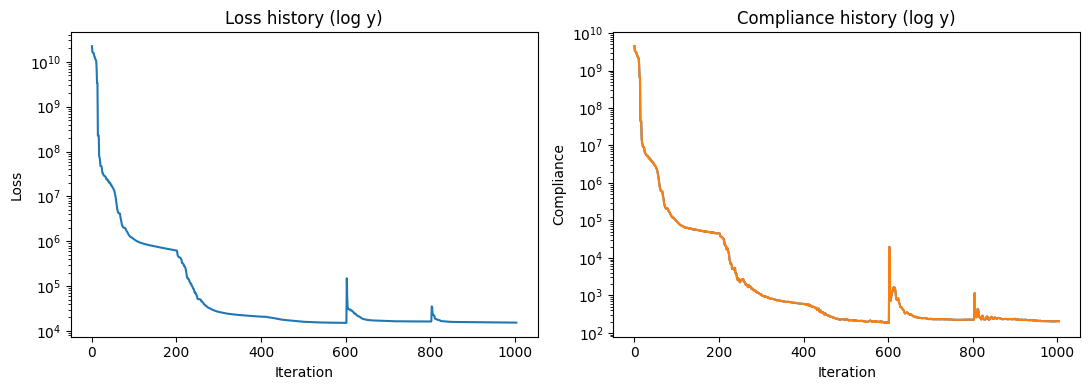

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# losses = np.loadtxt("losses_adam.txt")[::2]   # drop consecutive duplicates

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.semilogy(all_losses)                          # log y for the full 6-decade descent
ax1.set(xlabel="Iteration", ylabel="Loss", title="Loss history (log y)")

ax2.plot(all_compliances)        # linear y for fine structure
ax2.semilogy(all_compliances)                          # log y for the full 6-decade descent
ax2.set(xlabel="Iteration", ylabel="Compliance", title="Compliance history (log y)")
plt.tight_layout(); plt.show()

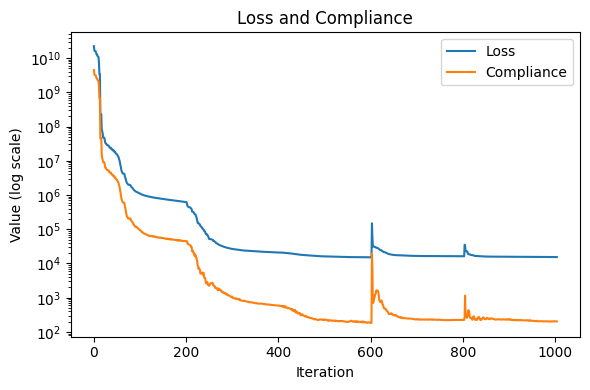

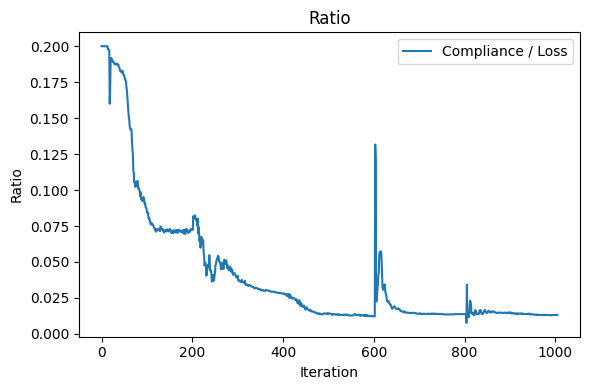

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# ========== Figure 1: Loss + Compliance ==========
plt.figure(figsize=(6, 4))

plt.semilogy(all_losses, label="Loss")
plt.semilogy(all_compliances, label="Compliance")

plt.xlabel("Iteration")
plt.ylabel("Value (log scale)")
plt.title("Loss and Compliance")
plt.legend()
plt.tight_layout()
plt.show()


# ========== Figure 2: Ratio ==========
ratio = np.array(all_compliances) / (np.array(all_losses) + 1e-12)

plt.figure(figsize=(6, 4))

plt.plot(ratio, label="Compliance / Loss")
plt.xlabel("Iteration")
plt.ylabel("Ratio")
plt.title("Ratio")
plt.legend()
plt.tight_layout()
plt.show()

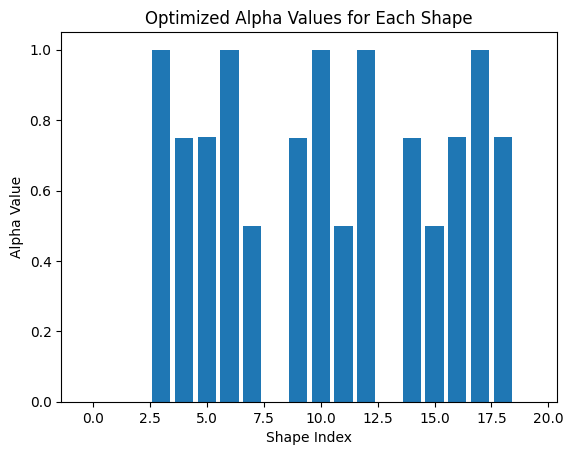

In [25]:
# show alphas
N = len(frames[-1]) // 4
alphas = frames[-1].reshape(4, N)[3]
plt.bar(range(N), alphas)
plt.xlabel("Shape Index")
plt.ylabel("Alpha Value")
plt.title("Optimized Alpha Values for Each Shape")
plt.show()


In [26]:
N = len(x_opt) // 4
final_lengs = alphas2lengths(alphas, beam_stock_prams)
print("Final lengths:", final_lengs)

nearest_idx = np.argmin(np.abs(final_lengs[:, None] - beam_stock_prams[None, :]), axis=1)
# reassign each length to the nearest stock length and recompute the density field
nearest_idx_alphas = (beam_stock_prams[nearest_idx] - beam_stock_prams[0]) / (beam_stock_prams[-1] - beam_stock_prams[0])
x_opt_reassigned = x_opt.copy()
x_opt_reassigned[3*N:4*N] = nearest_idx_alphas
# density_field_reassigned = density_func(x_opt_reassigned)

final_beam_lengths_distribution = np.bincount(nearest_idx, minlength=len(beam_stock_prams))

print("Final distribution:", final_beam_lengths_distribution)
print("Target distribution:", beam_stock_numbs)
print("Diff:", final_beam_lengths_distribution - beam_stock_numbs)


Final lengths: [ 0.          0.          0.         40.         29.98167596 30.02561262
 40.         19.99070207  0.         30.01521607 39.99307575 19.98023935
 40.          0.         30.02369631 20.01773079 30.03342382 40.
 30.03112584  0.        ]
Final distribution: [6 0 3 6 5]
Target distribution: [30  9  8  7  6]
Diff: [-24  -9  -5  -1  -1]


Final Loss: 203.4448334431715


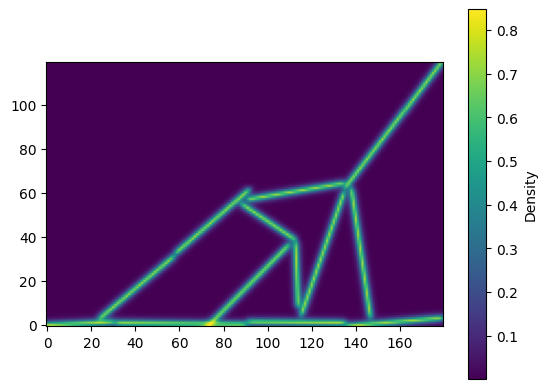

In [27]:
frame = frames[-1].copy()
density_field = params_to_density_map(
    frame,
    grid_w=grid_w, grid_h=grid_h,
    x_range=x_range, y_range=y_range,
    sdf_x_range=sdf_x_range, sdf_y_range=sdf_y_range, sharpness=sharpness
)

# density_field = density_from_joints
fig, ax = plt.subplots()
plt.colorbar(ax.imshow(density_field, origin='lower'), ax=ax, label='Density')
ax.imshow(density_field, origin='lower')
temp_density_field = density_field
temp_density_field[temp_density_field > 0.4] = 1
print("Final Loss:", env.objective(temp_density_field, volume_constraint=False)  )


joints: (34, 2)
pairs:  (20, 2)


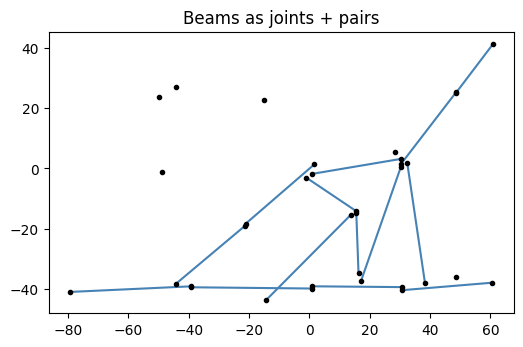

Beam lengths: [ 0.          0.          0.         40.         29.98167596 30.02561262
 40.         19.99070207  0.         30.01521607 39.99307575 19.98023935
 40.          0.         30.02369631 20.01773079 30.03342382 40.
 30.03112584  0.        ]


In [28]:
joint_xy_init, beam_joint_pairs = params_to_joints(frame)
print("joints:", joint_xy_init.shape)        # (M, 2)
print("pairs: ", beam_joint_pairs.shape)     # (N, 2)

plt.figure(figsize=(6, 4))
for i0, i1 in beam_joint_pairs:
    (x0, y0), (x1, y1) = joint_xy_init[i0], joint_xy_init[i1]
    plt.plot([x0, x1], [y0, y1], '-', color='steelblue')
plt.plot(joint_xy_init[:, 0], joint_xy_init[:, 1], 'ko', markersize=3)
plt.gca().set_aspect('equal')
plt.title('Beams as joints + pairs')
plt.show()

print("Beam lengths:", np.linalg.norm(joint_xy_init[beam_joint_pairs[:, 0]] - joint_xy_init[beam_joint_pairs[:, 1]], axis=1))


In [29]:
# j2, p2 = load_beam_txt("./results/result.txt")
save_beam_txt("./results/result_beam.txt", joint_xy_init, beam_joint_pairs)

In [30]:
from matplotlib.animation import FuncAnimation
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import HTML

def animate_frames(frames, shape=None, interval=100, save_path=None):
    if shape is None:
        shape = (grid_h, grid_w)

    cmap_bw = mcolors.LinearSegmentedColormap.from_list('density', ['white', '#111111'])

    fig, ax = plt.subplots(figsize=(8, 6), facecolor='white')
    fig.subplots_adjust(right=0.85)

    im = ax.imshow(frames[0].reshape(shape), cmap=cmap_bw, origin='lower', vmin=0, vmax=1)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

    cbar_ax = fig.add_axes([0.88, 0.12, 0.02, 0.76])
    cb = fig.colorbar(im, cax=cbar_ax)
    cb.set_label('Density', fontsize=11)
    cb.set_ticks([0, 0.5, 1.0])
    cb.set_ticklabels(['0', '0.5', '1'])

    def update(frame):
        im.set_array(frame.reshape(shape))
        return [im]

    anim = FuncAnimation(fig, update, frames=frames, interval=interval, blit=True)

    if save_path is not None:
        if save_path.endswith(".mp4"):
            anim.save(save_path, writer='ffmpeg', fps=1000//interval)
        elif save_path.endswith(".gif"):
            anim.save(save_path, writer='pillow', fps=1000//interval)
        else:
            raise ValueError("Unsupported format. Use .mp4 or .gif")

    plt.close(fig)
    return HTML(anim.to_jshtml())


import numpy as np
from scipy.ndimage import uniform_filter1d

raw = np.array(all_frames)                              # (T, 4*N)
# raw[0] = params_batch
# smooth = uniform_filter1d(raw, size=5, axis=0, mode='nearest')
anime_frames = [density_func(f) for f in raw[::5]]
animate_frames(anime_frames, save_path="./beam_result.gif")

In [31]:
# this is for video producing

def params_to_joints_v2(params_flat, tol=1e-6):
    N = len(params_flat) // 4
    x, y, theta, alpha = np.asarray(params_flat).reshape(4, N)

    half_h = alphas2lengths(alpha, beam_stock_prams) / 2.0

    dx = -np.sin(theta) * half_h
    dy =  np.cos(theta) * half_h
    p0 = np.stack([x - dx, y - dy], axis=1)
    p1 = np.stack([x + dx, y + dy], axis=1)
    endpoints = np.concatenate([p0, p1], axis=0)     # (2N, 2)

    joints, idx_of = [], np.empty(2 * N, dtype=int)
    for k, p in enumerate(endpoints):
        for j, q in enumerate(joints):
            if np.hypot(*(p - q)) < tol:
                idx_of[k] = j
                break
        else:
            idx_of[k] = len(joints)
            joints.append(p)

    joint_xy = np.array(joints, dtype=float)
    pairs = np.stack([idx_of[:N], idx_of[N:]], axis=1)
    return joint_xy, pairs


def save_frames_truss_txt(path, frames, stride=1, tol=1e-6, drop_zero_length=False):
    frames_sel = frames[::stride]
    with open(path, "w") as f:
        f.write("# n_frames\n")
        f.write(f"{len(frames_sel)}\n")
        for k, frame in enumerate(frames_sel):
            joint_xy, pairs = params_to_joints_v2(frame, tol=tol)

            if drop_zero_length:
                keep = pairs[:, 0] != pairs[:, 1]
                pairs = pairs[keep]
                used = np.unique(pairs)
                remap = -np.ones(len(joint_xy), dtype=int)
                remap[used] = np.arange(len(used))
                joint_xy = joint_xy[used]
                pairs = remap[pairs]

            f.write(f"# frame {k}\n")
            f.write("# joints (x y)\n")
            f.write(f"{len(joint_xy)}\n")
            for x, y in joint_xy:
                f.write(f"{x:.6f} {y:.6f}\n")
            f.write("# beams (i0 i1)\n")
            f.write(f"{len(pairs)}\n")
            for i0, i1 in pairs:
                f.write(f"{i0} {i1}\n")


def load_frames_truss_txt(path):
    """读回 -> list of (joint_xy (M,2), pairs (N,2))"""
    with open(path) as f:
        lines = [ln.strip() for ln in f if ln.strip() and not ln.startswith("#")]
    n_frames = int(lines[0])
    out, pos = [], 1
    for _ in range(n_frames):
        m = int(lines[pos]); pos += 1
        joint_xy = np.array([ln.split() for ln in lines[pos:pos + m]], dtype=float); pos += m
        n = int(lines[pos]); pos += 1
        pairs = np.array([ln.split() for ln in lines[pos:pos + n]], dtype=int); pos += n
        out.append((joint_xy, pairs))
    return out


save_frames_truss_txt("./results/video_data_beam.txt", all_frames, stride=1)
#save_frames_truss_txt("./results/frames_truss.txt", frames, stride=10)
